Dataset shape: (32686, 11)

column names: 
['UNIXTime', 'Data', 'Time', 'Radiation', 'Temperature', 'Pressure', 'Humidity', 'WindDirection(Degrees)', 'Speed', 'TimeSunRise', 'TimeSunSet']

First five rows : 
     UNIXTime                   Data      Time  Radiation  Temperature  \
0  1475229326  9/29/2016 12:00:00 AM  23:55:26       1.21           48   
1  1475229023  9/29/2016 12:00:00 AM  23:50:23       1.21           48   
2  1475228726  9/29/2016 12:00:00 AM  23:45:26       1.23           48   
3  1475228421  9/29/2016 12:00:00 AM  23:40:21       1.21           48   
4  1475228124  9/29/2016 12:00:00 AM  23:35:24       1.17           48   
5  1475227824  9/29/2016 12:00:00 AM  23:30:24       1.21           48   

   Pressure  Humidity  WindDirection(Degrees)  Speed TimeSunRise TimeSunSet  
0     30.46        59                  177.39   5.62    06:13:00   18:13:00  
1     30.46        58                  176.78   3.37    06:13:00   18:13:00  
2     30.46        57                  

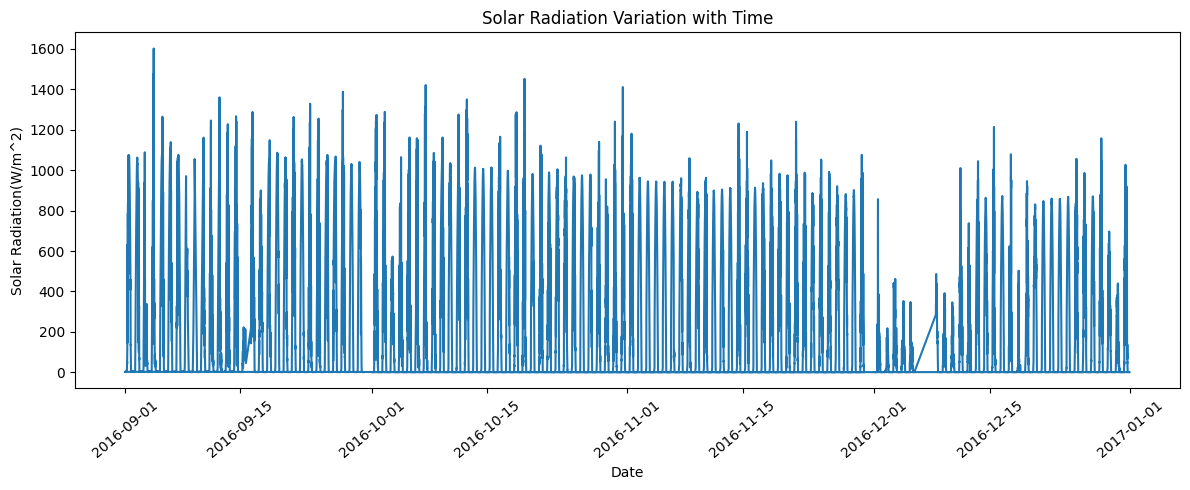



GRAPH 2: Radiation vs Temperature


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv('/SolarPrediction.csv')
print("Dataset shape:",df.shape)
print("\ncolumn names: ")
print(df.columns.tolist())

print("\nFirst five rows : ")
print(df.head(6))

print("\nMissing values: ")
print(df.isnull().sum())

# Convert Data to datetime
df["Data"] = pd.to_datetime(df["Data"],format="%m/%d/%Y %I:%M:%S %p",errors="coerce")

# Combine the date from Data with the time from Time
df["Datetime"] = pd.to_datetime(df["Data"].dt.strftime("%Y-%m-%d") + " " + df["Time"].astype(str),format="%Y-%m-%d %H:%M:%S",errors="coerce")

# Extract date and hour
df["Date"] = df["Datetime"].dt.date
df["Hour"] = df["Datetime"].dt.hour

print(df[["Data", "Time", "Datetime", "Date", "Hour"]].head(32686))
print("Invalid datetime values:", df["Datetime"].isna().sum())
print("Remaining rows:", len(df))

print()
print()
print('GRAPH 1: Radiation vs Date.')
Radiation = "Solar Radiation"

plt.figure(figsize=(12, 5))
plt.plot(df["Datetime"],df["Radiation"])
plt.xlabel("Date")
plt.ylabel("Solar Radiation(W/m^2)")
plt.title("Solar Radiation Variation with Time")
plt.xticks(rotation=40)
plt.tight_layout()
plt.savefig("01_radiation_over_time.png", dpi=300)
plt.show()
print()
print()


print("GRAPH 2: Radiation vs Temperature")
Temperature = "Temperature"

plt.figure(figsize=(7, 5))
plt.scatter(df["Temperature"], df["Radiation"],alpha=0.5)
plt.xlabel("Temperature(deg. F)")
plt.ylabel("Solar Radiation(W/m^2)")
plt.title("Solar Radiation vs Temperature")
plt.tight_layout()
plt.savefig("02_radiation_temperature.png", dpi=300)
plt.show()
print()
print()
print('GRAPH 3: Radiation vs Humidity')

Humidity= "Humidity"
plt.figure(figsize=(7, 5))
plt.scatter(df["WindDirection(Degrees)"], df["Radiation"], alpha=0.5)
plt.xlabel("Humidity(percent)")
plt.ylabel("Solar Radiation(W/m^2)")
plt.title("Solar Radiation vs Humidity")
plt.tight_layout()
plt.savefig("03_radiation_humidity.png", dpi=300)
plt.show()
print()
print()

print('Corellations: ','\nA.near 1:strong positive linear relationship.','\nB. near 0: weak linear relationship.','\nC. near -1: strong negative linear relationship.')
print()
cols = ["Radiation", "Temperature", 'Humidity']
print(df[cols].corr(numeric_only=True).round(3))
print()
hourly_radiation = df.groupby("Hour")["Radiation"].mean()

print(hourly_radiation)

print("Hour with highest average radiation:",hourly_radiation.idxmax())
print()
print()
#daily max and avg radiation
daily_report = df.groupby("Date").agg(daily_max_radiation=("Radiation", "max"),daily_avg_radiation=("Radiation", "mean"))
print(daily_report.head(10))
print()
print()
#date with highest radiation
print('Details for date with highest radiation: ')
peak_index = df["Radiation"].idxmax()
peak_row = df.loc[peak_index]

print("Peak observation:")
print(peak_row)

print("\nDate of highest radiation:", peak_row["Date"])
print("Time of highest radiation:", peak_row["Datetime"].time())
print("Maximum radiation:", peak_row["Radiation"])
print("Temperature:", peak_row["Temperature"])
print("Humidity:", peak_row["Humidity"])
print("windspeed: ", peak_row["Speed"])
print("Sunrise:", peak_row["TimeSunRise"])
print("Sunset:", peak_row["TimeSunSet"])
print('The duration after sunrise taken to reach maximum radiation: 12:15:04-06:08:00 = 06:15:04 ')

print()
print()

top_5_days = daily_report.sort_values("daily_avg_radiation",ascending=False).head(5)

print(top_5_days)

print()
print()


